# Frontera eficiente de Markowitz: el optimizador como maximizador de errores

**Perfil:** Gestión de portafolios  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

La frontera eficiente se calcula con medias y covarianzas **estimadas**. ¿Cuánto del desempeño que muestra la frontera en muestra es real? ¿Qué error pesa más (medias o covarianzas)? ¿Qué remedios (restricciones, contracción, remuestreo, mínima varianza) mejoran el desempeño **verdadero**?

## Recorrido

1. Mundo verdadero de 8 activos con parámetros conocidos; historias simuladas de distinta longitud.
2. **Versión 1:** Markowitz con medias y covarianza muestrales (con y sin restricciones).
3. **Diagnóstico:** optimismo en muestra, inestabilidad de pesos y atribución del error a medias vs covarianzas.
4. **Remedios:** contracción de Ledoit-Wolf, contracción de medias (Bayes-Stein), restricciones, remuestreo (Michaud) y mínima varianza.
5. Evaluación **verdadera** en 120 historias por longitud, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

## 2. El mundo verdadero

Ocho **activos riesgosos** (la tasa libre de riesgo $r_f=2\%$ se trata aparte) con retornos esperados y volatilidades anuales y una correlación que viene de **dos factores** (acciones y tasas), de modo que la matriz es definida positiva. Sus razones de Sharpe individuales son parecidas (0,14 a 0,42), de modo que la diversificación importa y no hay un activo que domine.

> *Nota de diseño:* una primera versión incluía un activo de "liquidez" (volatilidad 1 %, Sharpe 0,50). Dominaba todos los portafolios (80 % de la tangente y 97 % del GMV) y volvía trivial la comparación. Se eliminó: el efectivo se modela con $r_f$, no como un activo riesgoso más. Los retornos mensuales son normales multivariantes con esos parámetros. Como se **conocen** la media $\mu$ y la covarianza $\Sigma$ verdaderas, cualquier portafolio se puede evaluar **con exactitud**, sin ruido de muestreo.

In [2]:
ACT = ["acc_local", "acc_global", "acc_emerg", "bonos_gob", "bonos_corp", "alto_rend", "inmob", "materias"]
N_A = len(ACT)
MU = np.array([0.090, 0.080, 0.105, 0.045, 0.058, 0.070, 0.075, 0.050])        # anual
VOL = np.array([0.20, 0.16, 0.26, 0.07, 0.09, 0.12, 0.18, 0.22])
RF = 0.02
carg = np.array([[0.9, 0.0], [0.9, 0.1], [0.8, 0.1], [0.1, 0.8], [0.4, 0.5], [0.6, 0.35], [0.6, 0.3], [0.5, 0.0]])    # cargas en 2 factores (acciones, tasas)
d = np.sqrt(np.clip(1 - (carg ** 2).sum(axis=1), 0.05, None)); CORR = carg @ carg.T + np.diag(d ** 2); dd = np.sqrt(np.diag(CORR)); CORR = CORR / np.outer(dd, dd)
SIGMA = np.outer(VOL, VOL) * CORR
assert np.all(np.linalg.eigvalsh(SIGMA) > 0)
GAMMA = 5.0

def sharpe_v(w): return (w @ MU - RF) / np.sqrt(w @ SIGMA @ w)
def util_v(w): return w @ MU - 0.5 * GAMMA * (w @ SIGMA @ w)
def vol_v(w): return np.sqrt(w @ SIGMA @ w)

print(pd.DataFrame({"mu": MU, "vol": VOL, "sharpe_activo": (MU - RF) / VOL}, index=ACT).round(3).to_string())

               mu    vol  sharpe_activo
acc_local  0.0900 0.2000         0.3500
acc_global 0.0800 0.1600         0.3750
acc_emerg  0.1050 0.2600         0.3270
bonos_gob  0.0450 0.0700         0.3570
bonos_corp 0.0580 0.0900         0.4220
alto_rend  0.0700 0.1200         0.4170
inmob      0.0750 0.1800         0.3060
materias   0.0500 0.2200         0.1360


## 3. Herramientas de optimización

Dos problemas: **máximo Sharpe** (portafolio tangente) y **mínima varianza global**, con y sin restricciones (largo-solo, tope por activo). Las soluciones **sin restricciones** tienen forma cerrada:
$$w_{\text{GMV}}=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^\top\Sigma^{-1}\mathbf 1},\qquad w_{\text{tang}}\propto\Sigma^{-1}(\mu-r_f\mathbf 1).$$
Se usa el cierre para **verificar** al optimizador numérico.

In [3]:
def gmv_cerrado(S): x = np.linalg.solve(S, np.ones(len(S))); return x / x.sum()
def tang_cerrado(m, S, rf=RF): x = np.linalg.solve(S, m - rf); return x / x.sum()

def optimizar(m, S, objetivo="sharpe", largo=True, tope=1.0, rf=RF):
    n = len(m); lim = [(0.0 if largo else -2.0, tope if largo else 3.0)] * n
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    if objetivo == "sharpe": f = lambda w: -(w @ m - rf) / np.sqrt(w @ S @ w)
    else: f = lambda w: w @ S @ w
    mejor = None
    for x0 in (np.full(n, 1 / n), np.r_[np.full(n - 1, 0.0), 1.0]):
        r = minimize(f, x0, bounds=lim, constraints=cons, method="SLSQP", options={"maxiter": 400, "ftol": 1e-12})
        if r.success and (mejor is None or r.fun < mejor.fun): mejor = r
    return mejor.x

# verificacion: el optimizador numerico sin restricciones reproduce el cierre analitico
w_c = tang_cerrado(MU, SIGMA); w_n = optimizar(MU, SIGMA, "sharpe", largo=False, tope=1.0)
print("max |w_cerrado - w_numerico| (tangente, parametros verdaderos):", np.abs(w_c - w_n).max().round(6) if (w_c.min() > -2 and w_c.max() < 3) else "pesos fuera de la caja [-2,3]")
print("GMV cerrado vs numerico:", np.abs(gmv_cerrado(SIGMA) - optimizar(MU, SIGMA, "gmv", largo=False)).max().round(6))
verdad = {"tangente largo-solo": optimizar(MU, SIGMA, "sharpe", True), "GMV largo-solo": optimizar(MU, SIGMA, "gmv", True)}
tabla_ver = pd.DataFrame(verdad, index=ACT); tabla_ver.loc["Sharpe verdadero"] = [sharpe_v(w) for w in verdad.values()]; tabla_ver.loc["vol verdadera"] = [vol_v(w) for w in verdad.values()]
tabla_ver.round(3)

max |w_cerrado - w_numerico| (tangente, parametros verdaderos): 0.0
GMV cerrado vs numerico: 6e-06


,tangente largo-solo,GMV largo-solo
acc_local,0.0730,0.0020
acc_global,0.0640,0.0080
acc_emerg,0.0030,0.0000
bonos_gob,0.3710,0.6750
bonos_corp,0.3010,0.2190
alto_rend,0.1880,0.0510
inmob,0.0000,0.0000
materias,0.0000,0.0440
Sharpe verdadero,0.5370,0.4640
vol verdadera,0.0730,0.0640


## 4. Versión 1: Markowitz con parámetros muestrales

Con una historia de $T$ meses se estiman $\hat\mu$ y $\hat\Sigma$ y se optimiza como si fueran los parámetros verdaderos. Primero un caso concreto ($T=120$ meses, 10 años).

In [4]:
def historia(T, seed):
    rg = np.random.default_rng(seed)
    return rg.multivariate_normal(MU / 12, SIGMA / 12, T)

def estimar(R):
    return R.mean(axis=0) * 12, np.cov(R.T) * 12

R120 = historia(120, 11); mu_h, S_h = estimar(R120)
w_sh = optimizar(mu_h, S_h, "sharpe", True)
pd.DataFrame({"w_muestral": w_sh, "w_optimo_verdadero": verdad["tangente largo-solo"], "mu_hat": mu_h, "mu_verdadero": MU}, index=ACT).round(3)

,w_muestral,w_optimo_verdadero,mu_hat,mu_verdadero
acc_local,0.0000,0.0730,0.0730,0.0900
acc_global,0.0850,0.0640,0.1280,0.0800
acc_emerg,0.0000,0.0030,0.1340,0.1050
bonos_gob,0.0920,0.3710,0.0490,0.0450
bonos_corp,0.3530,0.3010,0.0750,0.0580
alto_rend,0.4400,0.1880,0.1090,0.0700
inmob,0.0300,0.0000,0.1160,0.0750
materias,0.0000,0.0000,0.0440,0.0500


In [5]:
sh_in = (w_sh @ mu_h - RF) / np.sqrt(w_sh @ S_h @ w_sh)
print(f"Sharpe EN MUESTRA del portafolio elegido: {sh_in:.3f}")
print(f"Sharpe VERDADERO del mismo portafolio:    {sharpe_v(w_sh):.3f}")
print(f"Sharpe verdadero del OPTIMO verdadero:    {sharpe_v(verdad['tangente largo-solo']):.3f}")
print(f"Volatilidad predicha por el modelo: {np.sqrt(w_sh @ S_h @ w_sh):.3f} | verdadera: {vol_v(w_sh):.3f}")

Sharpe EN MUESTRA del portafolio elegido: 0.890
Sharpe VERDADERO del mismo portafolio:    0.511
Sharpe verdadero del OPTIMO verdadero:    0.537
Volatilidad predicha por el modelo: 0.082 | verdadera: 0.087


### 4.1 La frontera "en muestra" frente a la frontera verdadera

Se calcula la frontera eficiente largo-solo con parámetros muestrales y se **reevalúa cada portafolio con los parámetros verdaderos**. La distancia entre ambas curvas es el costo del error de estimación.

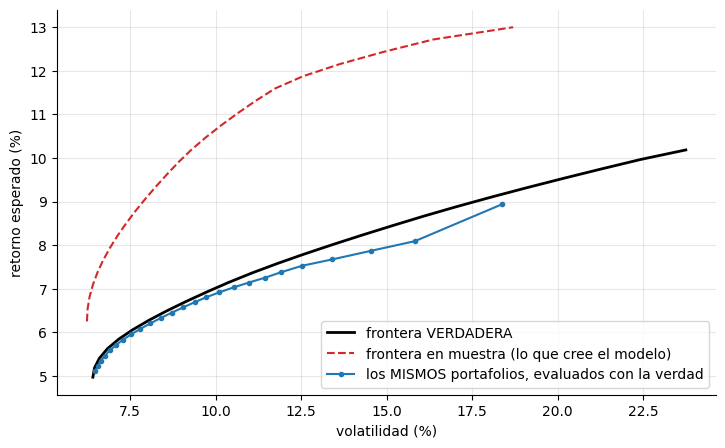

Lectura: el retorno esperado que el modelo atribuye a los portafolios de su frontera supera al verdadero en +44% en promedio (T=120).


In [6]:
def frontera(m, S, n=25):
    gm = optimizar(m, S, "gmv", True); r_min = gm @ m; r_max = m.max() * 0.97
    pts = []
    for objetivo in np.linspace(r_min, r_max, n):
        cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w, o=objetivo: w @ m - o}]
        r = minimize(lambda w: w @ S @ w, gm, bounds=[(0, 1)] * len(m), constraints=cons, method="SLSQP", options={"maxiter": 300, "ftol": 1e-12})
        if r.success: pts.append(r.x)
    return np.array(pts)

F_true = frontera(MU, SIGMA); F_hat = frontera(mu_h, S_h)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot([vol_v(w) * 100 for w in F_true], [w @ MU * 100 for w in F_true], "k-", lw=2, label="frontera VERDADERA")
ax.plot([np.sqrt(w @ S_h @ w) * 100 for w in F_hat], [w @ mu_h * 100 for w in F_hat], "C3--", label="frontera en muestra (lo que cree el modelo)")
ax.plot([vol_v(w) * 100 for w in F_hat], [w @ MU * 100 for w in F_hat], "C0-o", ms=3, label="los MISMOS portafolios, evaluados con la verdad")
ax.set_xlabel("volatilidad (%)"); ax.set_ylabel("retorno esperado (%)"); ax.legend(); plt.show()
opt_pct = np.mean([(w @ mu_h) / (w @ MU) - 1 for w in F_hat if (w @ MU) > 0.01]) * 100
print(f"Lectura: el retorno esperado que el modelo atribuye a los portafolios de su frontera supera al verdadero en {opt_pct:+.0f}% en promedio (T=120).")

## 5. Diagnóstico

### 5.1 Inestabilidad: ¿cuánto cambian los pesos entre historias?

Se generan 150 historias independientes de 120 meses y se optimiza en cada una. Se mide la dispersión de los pesos y la **rotación** entre historias.

In [7]:
def pesos_en_historias(T, R=150, seed0=0, **kw):
    W = []
    for i in range(R):
        m, S = estimar(historia(T, seed0 + i)); W.append(optimizar(m, S, **kw))
    return np.array(W)

W_t = pesos_en_historias(120, seed0=1000, objetivo="sharpe", largo=True)
W_g = pesos_en_historias(120, seed0=1000, objetivo="gmv", largo=True)
inest = pd.DataFrame({"tangente: peso medio": W_t.mean(0), "tangente: sd": W_t.std(0), "GMV: peso medio": W_g.mean(0), "GMV: sd": W_g.std(0)}, index=ACT)
inest.round(3)

,tangente: peso medio,tangente: sd,GMV: peso medio,GMV: sd
acc_local,0.0680,0.1370,0.0120,0.0210
acc_global,0.0740,0.1370,0.0150,0.0250
acc_emerg,0.0490,0.1160,0.0000,0.0030
bonos_gob,0.3350,0.2890,0.6770,0.0760
bonos_corp,0.2130,0.2660,0.2070,0.0740
alto_rend,0.1690,0.2270,0.0470,0.0500
inmob,0.0450,0.1070,0.0020,0.0070
materias,0.0480,0.1080,0.0400,0.0280


In [8]:
rot = lambda W: np.mean([0.5 * np.abs(W[i] - W[j]).sum() for i in range(40) for j in range(i + 1, 40)])
print("Lectura:")
print(f"  Rotacion media entre dos historias independientes (L1/2): tangente {rot(W_t):.2f} | GMV {rot(W_g):.2f}.")
print(f"  El Sharpe verdadero del portafolio tangente va de {min(sharpe_v(w) for w in W_t):.2f} a {max(sharpe_v(w) for w in W_t):.2f} segun la historia (optimo verdadero: {sharpe_v(verdad['tangente largo-solo']):.2f}).")
top_t = int(np.argmax(W_t.mean(0))); top_g = int(np.argmax(W_g.mean(0)))
print(f"  Peso medio del mayor activo: tangente '{ACT[top_t]}' {W_t.mean(0)[top_t]:.2f} (sd entre historias {W_t.std(0)[top_t]:.2f}) | GMV '{ACT[top_g]}' {W_g.mean(0)[top_g]:.2f} (sd {W_g.std(0)[top_g]:.2f}).")
print(f"  Numero efectivo de activos (1/sum w^2) de la tangente: {np.mean(1 / (W_t ** 2).sum(1)):.1f} de {N_A}; del GMV: {np.mean(1 / (W_g ** 2).sum(1)):.1f}.")

Lectura:
  Rotacion media entre dos historias independientes (L1/2): tangente 0.71 | GMV 0.15.
  El Sharpe verdadero del portafolio tangente va de 0.21 a 0.53 segun la historia (optimo verdadero: 0.54).
  Peso medio del mayor activo: tangente 'bonos_gob' 0.33 (sd entre historias 0.29) | GMV 'bonos_gob' 0.68 (sd 0.08).
  Numero efectivo de activos (1/sum w^2) de la tangente: 2.3 de 8; del GMV: 2.0.


### 5.2 ¿Qué error pesa más: las medias o las covarianzas?

Se cambia **un solo** insumo por vez: (a) medias estimadas con covarianza verdadera, (b) medias verdaderas con covarianza estimada, (c) ambas estimadas. Se mide el **Sharpe verdadero** del portafolio tangente largo-solo en 150 historias de 120 meses.

In [9]:
def sharpe_por_insumo(T, R=150, seed0=2000):
    filas = []
    for i in range(R):
        m, S = estimar(historia(T, seed0 + i))
        filas.append({"medias estimadas + cov verdadera": sharpe_v(optimizar(m, SIGMA, "sharpe", True)),
                      "medias verdaderas + cov estimada": sharpe_v(optimizar(MU, S, "sharpe", True)),
                      "ambas estimadas": sharpe_v(optimizar(m, S, "sharpe", True))})
    return pd.DataFrame(filas)

ins = sharpe_por_insumo(120)
techo = sharpe_v(verdad["tangente largo-solo"])
perd = (techo - ins.mean()).rename("perdida de Sharpe vs optimo").to_frame(); perd["% del techo"] = perd.iloc[:, 0] / techo * 100
print(f"Sharpe del optimo verdadero (techo): {techo:.3f}")
perd.round(3)

Sharpe del optimo verdadero (techo): 0.537


,perdida de Sharpe vs optimo,% del techo
medias estimadas + cov verdadera,0.0970,18.1190
medias verdaderas + cov estimada,0.0100,1.9550
ambas estimadas,0.1010,18.8270


In [10]:
a, b = perd.iloc[0, 0], perd.iloc[1, 0]
print(f"Lectura: el error en las MEDIAS cuesta {a:.3f} de Sharpe; el error en las COVARIANZAS, {b:.3f}. Las medias pesan {a / max(b, 1e-9):.1f} veces mas.")
print("Las medias de retornos se estiman con muchisimo menos precision que las covarianzas con la misma historia: el error de una media anual con 10 anios es ~ vol/sqrt(10), enorme frente a la propia media.")
print(f"Error estandar de la media anual de acc_local con T=120: {VOL[0] / np.sqrt(10):.3f} vs media verdadera {MU[0]:.3f} (relacion {VOL[0] / np.sqrt(10) / MU[0]:.1f}).")

Lectura: el error en las MEDIAS cuesta 0.097 de Sharpe; el error en las COVARIANZAS, 0.010. Las medias pesan 9.3 veces mas.
Las medias de retornos se estiman con muchisimo menos precision que las covarianzas con la misma historia: el error de una media anual con 10 anios es ~ vol/sqrt(10), enorme frente a la propia media.
Error estandar de la media anual de acc_local con T=120: 0.063 vs media verdadera 0.090 (relacion 0.7).


## 6. Remedios

Siete métodos, todos evaluados con los parámetros **verdaderos**:

1. **tang. sin restricciones** (cierre analítico, con posiciones cortas).
2. **tang. largo-solo** (versión 1).
3. **tang. largo-solo con tope de 30 %.**
4. **tang. con contracción:** medias de **Bayes-Stein** (Jorion) hacia la media del GMV y covarianza de **Ledoit-Wolf**.
5. **tang. remuestreada (Michaud):** promedio de los pesos óptimos sobre 8 remuestras *bootstrap* de la historia.
6. **GMV largo-solo** (no usa medias).
7. **GMV con Ledoit-Wolf.**

In [11]:
def bayes_stein(R):
    T, N = R.shape; m = R.mean(0) * 12; S = np.cov(R.T) * 12
    g = gmv_cerrado(S); m0 = g @ m
    d = m - m0; w = (N + 2) / ((N + 2) + T * d @ np.linalg.solve(S, d) / 12)
    return (1 - w) * m + w * m0, w

def lw_cov(R): return LedoitWolf().fit(R).covariance_ * 12

def metodos(R, rg):
    m, S = estimar(R); out = {}
    out["tang sin restricciones"] = tang_cerrado(m, S)
    out["tang largo-solo"] = optimizar(m, S, "sharpe", True)
    out["tang largo-solo tope 30%"] = optimizar(m, S, "sharpe", True, tope=0.30)
    mb, _ = bayes_stein(R); out["tang contraida (BS + LW)"] = optimizar(mb, lw_cov(R), "sharpe", True)
    pesos = []
    for _ in range(8):
        Rb = R[rg.integers(0, len(R), len(R))]; mb_, Sb = estimar(Rb); pesos.append(optimizar(mb_, Sb, "sharpe", True))
    out["tang remuestreada"] = np.mean(pesos, axis=0)
    out["GMV largo-solo"] = optimizar(m, S, "gmv", True)
    out["GMV con LW"] = optimizar(m, lw_cov(R), "gmv", True)
    return out

def experimento(T, R=100, seed0=0):
    filas = []
    for i in range(R):
        rg = np.random.default_rng(seed0 + i); W = metodos(historia(T, seed0 + i), rg)
        for nombre, w in W.items():
            filas.append({"T": T, "metodo": nombre, "sharpe": sharpe_v(w), "util": util_v(w), "vol": vol_v(w), "max_peso": np.abs(w).max(), "N_ef": 1 / (w ** 2).sum(), "w": w})
    return pd.DataFrame(filas)

res = {T: experimento(T, R=100, seed0=100 * T) for T in (60, 120, 240, 600)}
todo = pd.concat(res.values())
resumen = todo.groupby(["T", "metodo"]).agg(sharpe=("sharpe", "mean"), util=("util", "mean"), vol=("vol", "mean"), N_ef=("N_ef", "mean")).reset_index()
resumen.pivot(index="metodo", columns="T", values="sharpe").round(3)

T,60,120,240,600
metodo,,,,
GMV con LW,0.4890,0.4850,0.4760,0.4690
GMV largo-solo,0.4600,0.4660,0.4650,0.4650
tang contraida (BS + LW),0.4470,0.4620,0.4850,0.5030
tang largo-solo,0.4310,0.4380,0.4630,0.4910
tang largo-solo tope 30%,0.4540,0.4570,0.4780,0.5000
tang remuestreada,0.4500,0.4560,0.4730,0.4950
tang sin restricciones,0.1890,0.2670,0.3440,0.4380


In [12]:
print("Utilidad de media-varianza (CE, gamma=5) por metodo y longitud de historia:")
resumen.pivot(index="metodo", columns="T", values="util").round(4)

Utilidad de media-varianza (CE, gamma=5) por metodo y longitud de historia:


T,60,120,240,600
metodo,,,,
GMV con LW,0.0415,0.0410,0.0403,0.0399
GMV largo-solo,0.0394,0.0398,0.0396,0.0395
tang contraida (BS + LW),0.0323,0.0361,0.0417,0.0432
tang largo-solo,0.0334,0.0345,0.0396,0.0430
tang largo-solo tope 30%,0.0382,0.0389,0.0416,0.0441
tang remuestreada,0.0378,0.0384,0.0412,0.0433
tang sin restricciones,-3.9826,-1.6763,-0.4270,0.0328


In [13]:
techo_u = max(util_v(verdad["tangente largo-solo"]), util_v(optimizar(MU, SIGMA, "sharpe", True)))
rot_tab = {}
for T, df in res.items():
    for m in df["metodo"].unique():
        W = np.vstack(df[df["metodo"] == m]["w"].to_list()); rot_tab[(m, T)] = np.mean([0.5 * np.abs(W[i] - W[j]).sum() for i in range(30) for j in range(i + 1, 30)])
rot_df = pd.Series(rot_tab).unstack()
print(f"Sharpe del optimo verdadero (largo-solo): {sharpe_v(verdad['tangente largo-solo']):.3f} | Sharpe del GMV verdadero: {sharpe_v(verdad['GMV largo-solo']):.3f}")
print("\nRotacion de pesos entre historias (L1/2), por metodo y longitud:")
rot_df.round(2)

Sharpe del optimo verdadero (largo-solo): 0.537 | Sharpe del GMV verdadero: 0.464

Rotacion de pesos entre historias (L1/2), por metodo y longitud:


,60,120,240,600
GMV con LW,0.1800,0.1400,0.1000,0.0700
GMV largo-solo,0.2300,0.1700,0.1100,0.0700
tang contraida (BS + LW),0.6500,0.5400,0.4100,0.3500
tang largo-solo,0.7200,0.6800,0.6100,0.5400
tang largo-solo tope 30%,0.4700,0.4400,0.4100,0.3100
tang remuestreada,0.5600,0.5500,0.5200,0.4400
tang sin restricciones,16.5400,4.2800,2.4500,1.0900


In [14]:
sh = resumen.pivot(index="metodo", columns="T", values="sharpe")
print("Lectura (Sharpe VERDADERO medio):")
for T in sh.columns:
    mejor = sh[T].idxmax(); peor = sh[T].idxmin()
    print(f"  T={T:<4d}: mejor '{mejor}' ({sh.loc[mejor, T]:.3f}); peor '{peor}' ({sh.loc[peor, T]:.3f}).")
print(f"  La version 1 (tang largo-solo) logra {sh.loc['tang largo-solo', 60]:.3f} con T=60 y {sh.loc['tang largo-solo', 600]:.3f} con T=600 (optimo verdadero {sharpe_v(verdad['tangente largo-solo']):.3f}).")
print(f"  Sin restricciones: {sh.loc['tang sin restricciones', 60]:.3f} con T=60 y utilidad media {resumen.pivot(index='metodo', columns='T', values='util').loc['tang sin restricciones', 60]:.3f} (negativa): las posiciones cortas extremas arruinan el resultado.")
tang = [m for m in sh.index if m.startswith("tang")]
mejor_tang = {T: sh.loc[tang, T].idxmax() for T in sh.columns}
cruce = [T for T in sh.columns if sh.loc[mejor_tang[T], T] > sh.loc["GMV con LW", T]]
print(f"  Mejor variante de tangente por T: " + ", ".join(f"T={T}: {mejor_tang[T]} ({sh.loc[mejor_tang[T], T]:.3f} vs GMV-LW {sh.loc['GMV con LW', T]:.3f})" for T in sh.columns))
print(f"  La tangente (con su mejor remedio) supera al GMV con Ledoit-Wolf solo con T >= {cruce[0] if cruce else 'ninguno de los probados'}: con historias cortas, NO usar las medias gana.")
gv = sharpe_v(verdad["GMV largo-solo"])
print(f"  Curiosidad: el GMV con Ledoit-Wolf logra Sharpe {sh.loc['GMV con LW', 60]:.3f} (T=60), MAYOR que el del GMV verdadero ({gv:.3f}): la contraccion lo diversifica hacia activos con mejor Sharpe. Un estimador sesgado puede superar al optimo exacto de OTRO criterio.")

Lectura (Sharpe VERDADERO medio):
  T=60  : mejor 'GMV con LW' (0.489); peor 'tang sin restricciones' (0.189).
  T=120 : mejor 'GMV con LW' (0.485); peor 'tang sin restricciones' (0.267).
  T=240 : mejor 'tang contraida (BS + LW)' (0.485); peor 'tang sin restricciones' (0.344).
  T=600 : mejor 'tang contraida (BS + LW)' (0.503); peor 'tang sin restricciones' (0.438).
  La version 1 (tang largo-solo) logra 0.431 con T=60 y 0.491 con T=600 (optimo verdadero 0.537).
  Sin restricciones: 0.189 con T=60 y utilidad media -3.983 (negativa): las posiciones cortas extremas arruinan el resultado.
  Mejor variante de tangente por T: T=60: tang largo-solo tope 30% (0.454 vs GMV-LW 0.489), T=120: tang contraida (BS + LW) (0.462 vs GMV-LW 0.485), T=240: tang contraida (BS + LW) (0.485 vs GMV-LW 0.476), T=600: tang contraida (BS + LW) (0.503 vs GMV-LW 0.469)
  La tangente (con su mejor remedio) supera al GMV con Ledoit-Wolf solo con T >= 240: con historias cortas, NO usar las medias gana.
  Curiosida

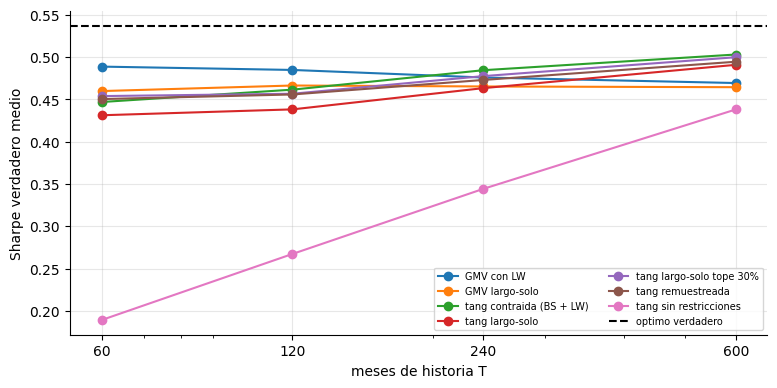

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for m in sh.index: ax.plot(sh.columns, sh.loc[m], "o-", label=m)
ax.axhline(sharpe_v(verdad["tangente largo-solo"]), color="k", ls="--", label="optimo verdadero"); ax.set_xscale("log"); ax.set_xticks(list(sh.columns)); ax.set_xticklabels(list(sh.columns))
ax.set_xlabel("meses de historia T"); ax.set_ylabel("Sharpe verdadero medio"); ax.legend(fontsize=7, ncol=2); plt.show()

## 7. Pruebas automáticas

In [16]:
# 7.1 el optimizador numerico coincide con el cierre analitico (cuando las soluciones caben en la caja)
assert np.abs(gmv_cerrado(SIGMA) - optimizar(MU, SIGMA, "gmv", largo=False)).max() < 1e-4
# 7.2 propiedades de los portafolios: suma 1; largo-solo no negativos; el tope se respeta
for nombre, df in todo.groupby("metodo"):
    for w in df["w"]:
        assert abs(w.sum() - 1) < 1e-6, nombre
        if nombre != "tang sin restricciones": assert (w >= -1e-6).all(), nombre
assert all((w <= 0.30 + 1e-6).all() for w in todo[todo["metodo"] == "tang largo-solo tope 30%"]["w"])
# 7.3 el GMV tiene la menor varianza verdadera entre los portafolios de la frontera verdadera
vmin = min(vol_v(w) for w in F_true); assert abs(vol_v(verdad["GMV largo-solo"]) - vmin) < 5e-4
# 7.4 la frontera verdadera es creciente en retorno y volatilidad
fv = [(vol_v(w), w @ MU) for w in F_true]; assert all(fv[i][1] <= fv[i + 1][1] + 1e-9 for i in range(len(fv) - 1)) and all(fv[i][0] <= fv[i + 1][0] + 1e-6 for i in range(len(fv) - 1))
# 7.5 optimismo en muestra: el modelo cree obtener mas de lo que obtiene, y subestima la volatilidad
assert sh_in > sharpe_v(w_sh) and np.sqrt(w_sh @ S_h @ w_sh) < vol_v(w_sh) * 1.05
assert opt_pct > 5
# 7.6 ningun portafolio supera al optimo verdadero en Sharpe
assert (todo["sharpe"] <= sharpe_v(verdad["tangente largo-solo"]) + 1e-6).all()
# 7.7 las medias pesan mas que las covarianzas en el error
assert perd.iloc[0, 0] > 2 * perd.iloc[1, 0]
# 7.8 el GMV es mas estable que la tangente (menos rotacion) y el sharpe verdadero mejora con T para el tangente largo-solo
assert rot(W_g) < rot(W_t)
assert sh.loc["tang largo-solo", 600] > sh.loc["tang largo-solo", 60]
# 7.9 la contraccion y el remuestreo mejoran el Sharpe verdadero del largo-solo con T corto
assert sh.loc["tang contraida (BS + LW)", 60] > sh.loc["tang largo-solo", 60]
assert rot_df.loc["tang remuestreada", 120] < rot_df.loc["tang largo-solo", 120]
# 7.9b con historias cortas, evitar las medias gana; con historias largas, la tangente con remedio supera al GMV
assert all(sh.loc["GMV con LW", T] > sh.loc[tang, T].max() for T in (60, 120)), "con T<=120 el GMV con LW debe superar a toda tangente"
assert sh.loc[tang, 600].max() > sh.loc["GMV con LW", 600] and sh.loc["tang contraida (BS + LW)", 240] > sh.loc["GMV con LW", 240]
assert (sh.loc["GMV con LW"] > gv).all(), "el GMV con LW debe superar el Sharpe del GMV verdadero (diversificacion)"
# 7.9c la utilidad de la tangente sin restricciones es negativa con historias cortas
assert resumen.pivot(index="metodo", columns="T", values="util").loc["tang sin restricciones", 60] < 0
# 7.10 el Sharpe de la tangente sin restricciones con T corto es peor que el de la largo-solo (posiciones extremas)
assert sh.loc["tang sin restricciones", 60] < sh.loc["tang largo-solo", 60]
# 7.11 Bayes-Stein: el factor de contraccion esta en [0,1]; Ledoit-Wolf da covarianza definida positiva
mbs, wbs = bayes_stein(historia(120, 3)); assert 0 <= wbs <= 1 and np.all(np.linalg.eigvalsh(lw_cov(historia(120, 3))) > 0)
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: Markowitz muestral | Sharpe en muestra 0,89 frente a 0,51 verdadero; la frontera estimada atribuye ≈ 44 % más retorno del real. Sin restricciones y con T=60 la utilidad es negativa | No tomar la frontera estimada como la alcanzable |
| Inestabilidad | La rotación entre historias es ≈ 0,71 en la tangente y ≈ 0,15 en el GMV (T=120); la tangente concentra el peso en pocos activos (≈ 2,3 efectivos de 8) | Medir la rotación de pesos, no solo el Sharpe |
| Medias vs covarianzas | El error en las medias cuesta ≈ 0,10 de Sharpe frente a ≈ 0,01 el de las covarianzas (≈ 9×) | Invertir esfuerzo en estabilizar las medias o evitarlas |
| Remedios | Con T ≤ 120 meses el GMV con Ledoit-Wolf (Sharpe ≈ 0,49) supera a toda variante de tangente (la mejor ≈ 0,46); con T ≥ 240 la tangente contraída lo supera | Con historias cortas, evitar estimar las medias; con largas, contraer |
| Longitud de historia | Con más datos todos convergen hacia el óptimo; con pocos, las diferencias son grandes | Calibrar la ambición del optimizador a la historia disponible |

**Límites que no deben ocultarse**

- Los retornos son normales e independientes en el tiempo; las series reales tienen colas pesadas, autocorrelación de volatilidad y cambios de régimen.
- Los parámetros verdaderos son constantes; en la práctica cambian, y la historia puede no representar el futuro.
- Los retornos esperados verdaderos y sus diferencias son una elección del autor: con diferencias de Sharpe más pequeñas entre activos, ningún método bate fácilmente a pesos iguales.
- No se incluyen costos de transacción ni rebalanceo (ver el notebook de backtest).
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.